# Derivadas, aproximaciones y extremos

## Objetivo
Derivar desde cocientes incrementales, comparar errores y optimizar con y sin restricciones.

**Datos:** ejemplos analíticos o simulaciones didácticas; no representan clientes ni estimaciones de mercado.

## Preparación
Python 3.11 o posterior, NumPy, SciPy y Matplotlib. Todo se genera aquí; no necesita internet. Lee la fórmula y predice el resultado antes de ejecutar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': plt.cycler(color=['#285A8E','#C77C36','#687D45'])})
rng = np.random.default_rng(20261025)


## 1. Aproximar una pendiente

Para $f(x)=e^x$, $f\prime(1)=e$. La diferencia hacia adelante es $[f(x+h)-f(x)]/h$ y la central $[f(x+h)-f(x-h)]/(2h)$. Taylor explica errores de truncamiento de orden $h$ y $h^2$, respectivamente, cuando hay suficiente regularidad.

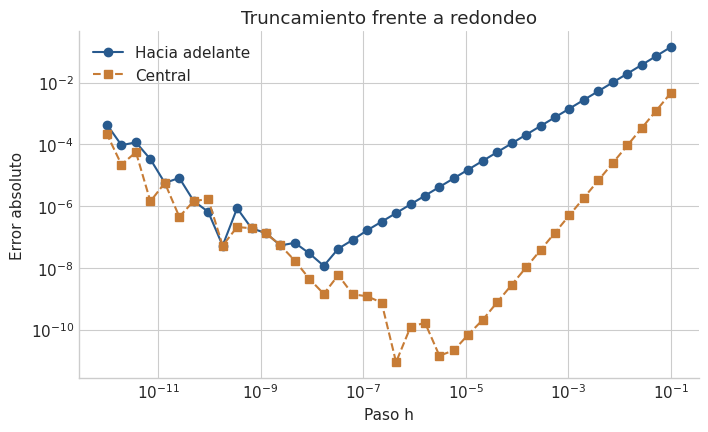

Menor error central: 8.880451929371702e-12


In [2]:
hs=np.logspace(-1,-12,40)
adelante=(np.exp(1+hs)-np.exp(1))/hs
central=(np.exp(1+hs)-np.exp(1-hs))/(2*hs)
fig,ax=plt.subplots()
ax.loglog(hs,np.abs(adelante-np.e),'o-',label='Hacia adelante')
ax.loglog(hs,np.abs(central-np.e),'s--',label='Central')
ax.set(xlabel='Paso h',ylabel='Error absoluto',title='Truncamiento frente a redondeo')
ax.legend(); plt.show()
print('Menor error central:',np.min(np.abs(central-np.e)))

**Lectura del resultado.** El error disminuye hasta que domina el redondeo por restar números próximos. La forma exacta depende de la plataforma; un paso menor no siempre mejora.

## 2. Encontrar un extremo y mirar el dominio

$\pi(q)=10q-q^2-9=16-(q-5)^2$. Su derivada $10-2q$ se anula en 5 y la segunda derivada es -2. En $[0,3]$ el candidato 5 es inviable, así que debemos comparar los bordes.

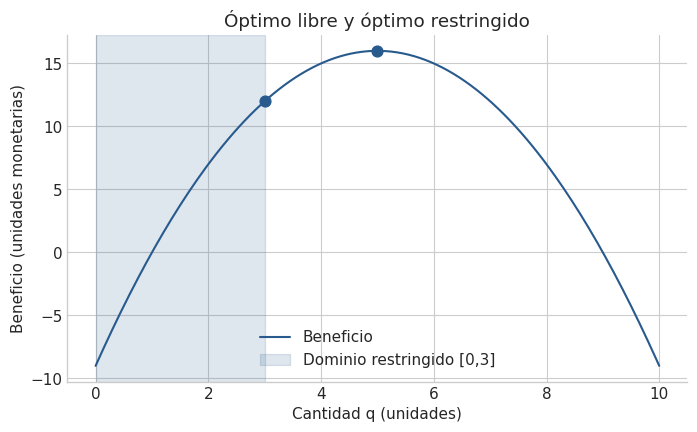

Óptimo libre: 16 Óptimo restringido: 12


In [3]:
q=np.linspace(0,10,201)
beneficio=lambda q: 10*q-q*q-9
fig,ax=plt.subplots()
ax.plot(q,beneficio(q),label='Beneficio')
ax.axvspan(0,3,alpha=.15,color='#285A8E',label='Dominio restringido [0,3]')
ax.scatter([3,5],[beneficio(3),beneficio(5)],s=60)
ax.set(xlabel='Cantidad q (unidades)',ylabel='Beneficio (unidades monetarias)',title='Óptimo libre y óptimo restringido')
ax.legend(); plt.show()
print('Óptimo libre:',beneficio(5),'Óptimo restringido:',beneficio(3))

**Lectura del resultado.** El óptimo libre vale 16; restringiendo a q≤3, el mejor valor es 12. La condición de primer orden no basta sin revisar factibilidad.

## Practica antes de ver la solución

¿Por qué x³ no tiene mínimo ni máximo en cero aunque su derivada sea cero? ¿Y |x|?

In [4]:
# Escribe aquí tu razonamiento y tu cálculo.


## Solución razonada

x³ cambia de signo al atravesar cero y crece a ambos lados: es un punto estacionario sin extremo. |x| tiene mínimo global en cero aunque allí no es derivable.

## Comprobaciones

Estas pruebas contrastan identidades, referencias analíticas y tolerancias; no prueban teoremas ni validan modelos reales.

In [5]:
assert np.min(np.abs(central-np.e))<1e-7
assert beneficio(5)==16 and beneficio(3)==12
assert np.all(beneficio(q)<=16+1e-12)
assert (-.1)**3<0<(.1)**3
print('Referencias analíticas y dominio: OK')

Referencias analíticas y dominio: OK


## Siguiente paso

Cambia un parámetro, anticipa el efecto y explica por qué ocurre. Vuelve a ejecutar desde un kernel limpio. Consulta el índice del curso para la lección teórica relacionada.